# 3 · Caso Gama — cenários, sensibilidade e taxa ajustada ao risco

O enunciado não fala de risco, mas o board vai perguntar: *"e se as vendas vierem abaixo do previsto?"*
Seguindo as notas de Análise de Risco, construímos cenários **pessimista / mais provável / otimista** com
probabilidades (25% / 50% / 25%), calculamos o valor esperado, o desvio padrão e o coeficiente de variação
do VPL de cada projeto e ajustamos a taxa de desconto ao risco.

A chave é descrever cada projeto como **função de um dicionário de parâmetros**: o mesmo modelo serve para o
caso-base, para cada cenário e, no notebook 4, para a simulação de Monte Carlo.

In [1]:
import numpy as np
import pandas as pd

from greenseer import *
from greenseer import viz

viz.configurar_notebook()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

K, IR = 0.18, 0.20
SAIDA = "../outputs/03"

## 1. Modelos parametrizados

Os parâmetros com maior incerteza em cada projeto viram chaves do dicionário `p`. Tudo o que não é
incerto fica fixo no modelo. (Estas funções também estão em `caso_gama.py`, usado pelo notebook 4.)

In [2]:
def modelo_p1(p):
    return Projeto("P1", 5, investimento=p["p1_investimento"],
                   receitas=Produto(p["p1_unidades"], p["p1_preco"]),
                   custos={"Custo variável": Produto(p["p1_unidades"], p["p1_custo_var"])},
                   aliquota_ir=p["ir"])

def modelo_p2(p):
    receitas = np.asarray([570_000, 550_000, 510_000, 423_000, 423_000]) * p["p2_fator_receita"]
    return Projeto("P2", 5, investimento=p["p2_investimento"], receitas=receitas,
                   custos={"CPV": Percentual(p["p2_cpv"]), "Despesas administrativas (10%)": Percentual(0.10),
                           "Despesas de vendas (9%)": Percentual(0.09), "Despesas gerais": [17_200, 19_250, 23_350, 36_330, 36_330]},
                   aliquota_ir=p["ir"])

def modelo_p3(p):
    cpv = np.asarray([0.67, 0.63, 0.63, 0.61, 0.60, 0.58, 0.58]) + p["p3_cpv_delta"]
    return Projeto("P3", 7, investimento=p["p3_investimento"],
                   receitas=Produto(Crescimento(60_000, p["p3_crescimento"], periodos=5), p["p3_preco"]),
                   custos={"CPV": Percentual(cpv), "Despesas operacionais": Percentual([0.25, 0.23, 0.23, 0.23, 0.21, 0.17, 0.17])},
                   depreciacao=Depreciacao.explicita(30_000), valor_residual=ValorResidual.mercado(p["p3_valor_residual"]),
                   aliquota_ir=p["ir"])

def modelo_p4(p):
    unidades = Variacoes(p["p4_unidades"], {2: -0.02, 3: -0.02, 4: -0.03})
    preco = Variacoes(p["p4_preco"], {4: -0.05, 6: -0.04})
    return Projeto("P4", 6, investimento=p["p4_investimento"], receitas=Produto(unidades, preco),
                   custos={"Custo fixo": p["p4_custo_fixo"], "Custo variável": Produto(unidades, p["p4_custo_var"])},
                   valor_residual=ValorResidual.perpetuidade(K), aliquota_ir=p["ir"])

modelos = {"P1": modelo_p1, "P2": modelo_p2, "P3": modelo_p3, "P4": modelo_p4}

base = dict(
    ir=IR,
    p1_unidades=12_500, p1_preco=12.0, p1_custo_var=5.80, p1_investimento=200_000,
    p2_fator_receita=1.0, p2_cpv=0.60, p2_investimento=200_000,
    p3_crescimento=0.10, p3_preco=6.0, p3_cpv_delta=0.0, p3_valor_residual=42_000, p3_investimento=225_000,
    p4_unidades=30_000, p4_preco=20.0, p4_custo_fixo=200_000, p4_custo_var=9.0, p4_investimento=300_000,
)
rotulos = {
    "ir": "Alíquota de IR", "p1_unidades": "P1 · unidades/ano", "p1_preco": "P1 · preço", "p1_custo_var": "P1 · custo variável", "p1_investimento": "P1 · investimento",
    "p2_fator_receita": "P2 · fator de receita", "p2_cpv": "P2 · CPV %", "p2_investimento": "P2 · investimento",
    "p3_crescimento": "P3 · crescimento a.a.", "p3_preco": "P3 · preço", "p3_cpv_delta": "P3 · CPV (± p.p.)", "p3_valor_residual": "P3 · valor residual", "p3_investimento": "P3 · investimento",
    "p4_unidades": "P4 · unidades ano 1", "p4_preco": "P4 · preço ano 1", "p4_custo_fixo": "P4 · custo fixo", "p4_custo_var": "P4 · custo variável", "p4_investimento": "P4 · investimento",
}

# conferência: o caso-base reproduz o notebook 2
estilizar(tabela_indicadores([m(base) for m in modelos.values()], K)[["investimento", "vida", "vpl", "tir", "rau", "ibc"]], titulo="Caso-base (igual ao notebook 2)")

,Investimento,Vida (anos),VPL,TIR,RAU,IBC
Projeto,,,,,,
P1,$ 200.000,5,$ 18.902,"22,11%",$ 6.044,"1,09"
P2,$ 200.000,5,$ 30.609,"25,46%",$ 9.788,"1,15"
P3,$ 225.000,7,$ 36.440,"22,19%",$ 9.561,"1,16"
P4,$ 300.000,6,$ 42.350,"23,82%",$ 12.108,"1,14"


## 2. Cenários com probabilidades

As premissas de cada cenário refletem o que mais pode dar errado (ou certo) em cada projeto: volume e custo
em P1, nível de receita e CPV em P2, crescimento, CPV e valor residual em P3, volume, preço e custo fixo em P4.

In [3]:
cenarios = [
    Cenario("Pessimista", dict(
        p1_unidades=10_500, p1_custo_var=6.30,
        p2_fator_receita=0.90, p2_cpv=0.63,
        p3_crescimento=0.05, p3_cpv_delta=+0.03, p3_valor_residual=30_000,
        p4_unidades=27_000, p4_preco=19.0, p4_custo_fixo=215_000,
    ), probabilidade=0.25, descricao="demanda fraca, custos pressionados"),
    Cenario("Mais provável", {}, probabilidade=0.50, descricao="enunciado"),
    Cenario("Otimista", dict(
        p1_unidades=14_000, p1_custo_var=5.50,
        p2_fator_receita=1.08, p2_cpv=0.58,
        p3_crescimento=0.13, p3_cpv_delta=-0.02, p3_valor_residual=50_000,
        p4_unidades=32_000, p4_preco=21.0, p4_custo_fixo=195_000,
    ), probabilidade=0.25, descricao="demanda forte, ganhos de eficiência"),
]
ac = AnaliseDeCenarios(modelos, base, cenarios, taxa=K)
resultado = ac.executar()
estilizar(ac.tabela("vpl"), tipos={c.nome: "moeda" for c in cenarios}, destacar=[], titulo="VPL por cenário ($)")

Cenário,Pessimista,Mais provável,Otimista
Projeto,,,
P1,($ 25.254),$ 18.902,$ 52.675
P2,($ 30.506),$ 30.609,$ 79.501
P3,($ 34.126),$ 36.440,$ 88.713
P4,($ 261.089),$ 42.350,$ 278.894


In [4]:
estilizar(ac.tabela("tir"), tipos={c.nome: "pct" for c in cenarios}, destacar=[], titulo="TIR por cenário")

Cenário,Pessimista,Mais provável,Otimista
Projeto,,,
P1,"12,29%","22,11%","29,16%"
P2,"10,08%","25,46%","36,67%"
P3,"13,69%","22,19%","27,61%"
P4,—,"23,82%","47,89%"


In [5]:
resumo = ac.resumo("vpl")
estilizar(resumo, titulo="Valor esperado, desvio padrão e coeficiente de variação do VPL")

,Valor esperado,Desvio padrão,CV,Mínimo,Máximo,P(< 0)
Projeto,,,,,,
P1,$ 16.306,$ 27.674,"1,70",($ 25.254),$ 52.675,"25,00%"
P2,$ 27.553,$ 39.013,"1,42",($ 30.506),$ 79.501,"25,00%"
P3,$ 31.867,$ 43.670,"1,37",($ 34.126),$ 88.713,"25,00%"
P4,$ 25.626,$ 191.644,"7,48",($ 261.089),$ 278.894,"25,00%"


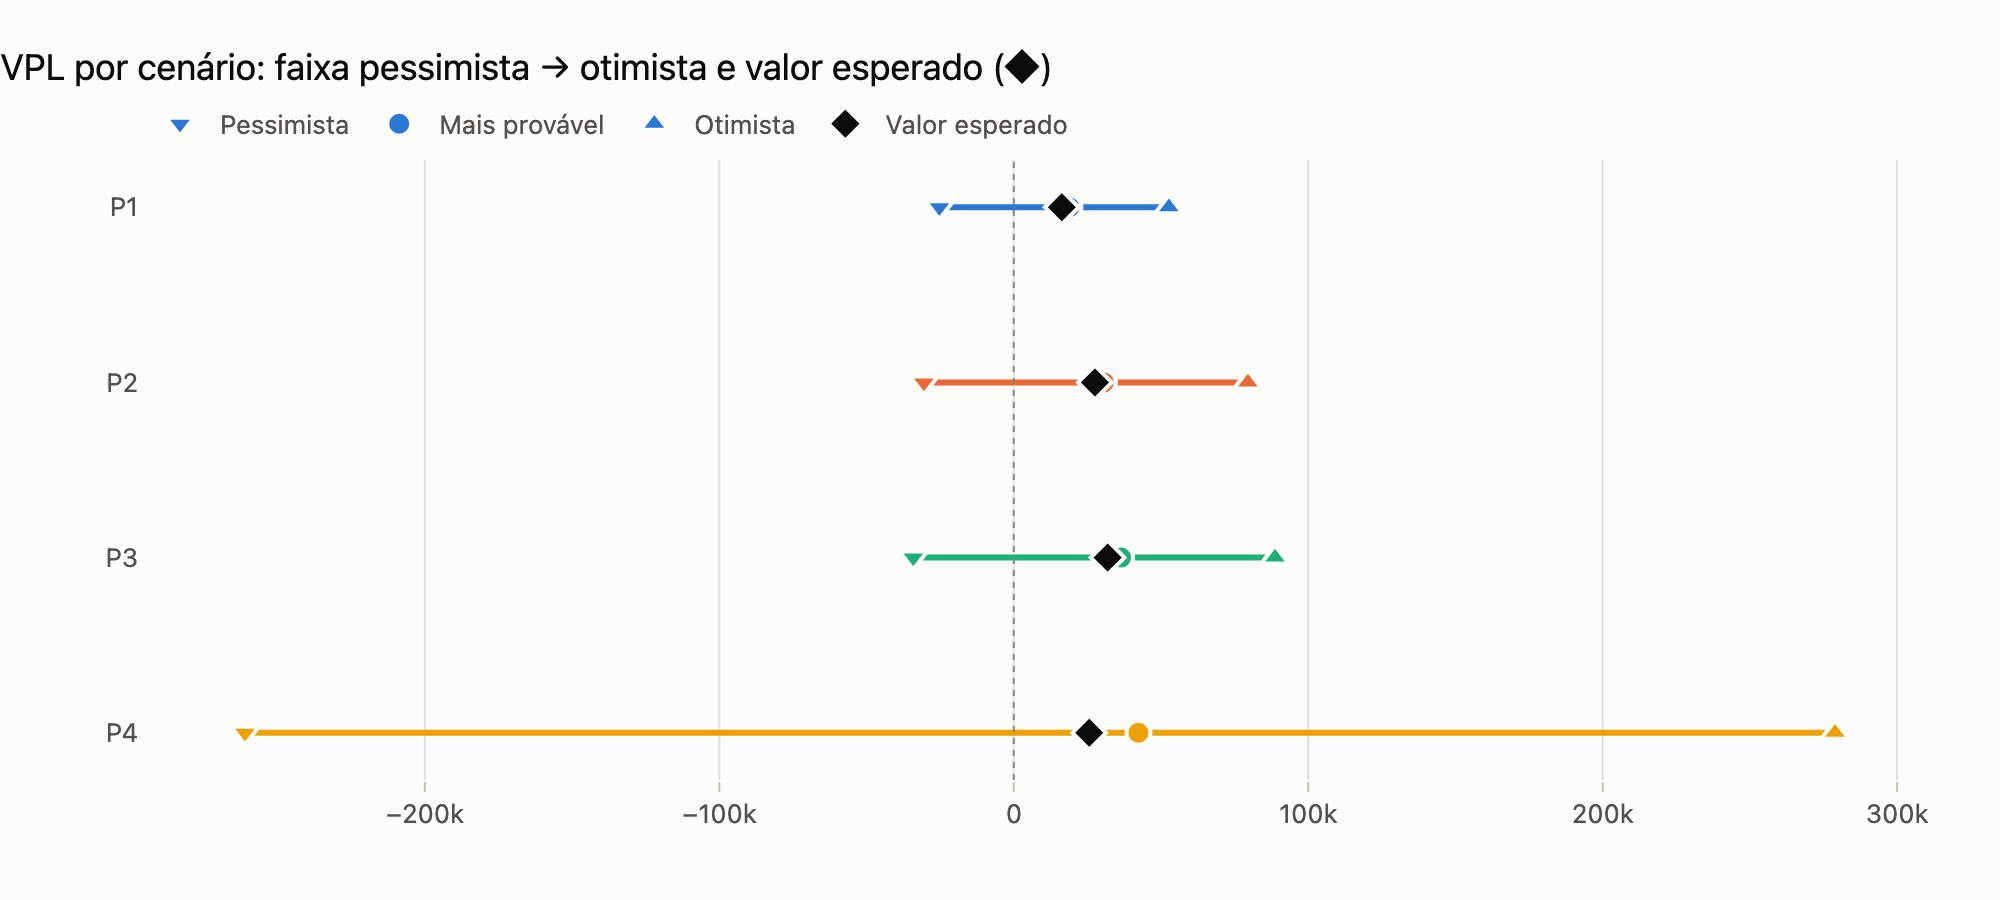

In [6]:
fig = viz.grafico_cenarios(resultado, "vpl", resumo, titulo="VPL por cenário: faixa pessimista → otimista e valor esperado (◆)")
viz.exportar(fig, f"{SAIDA}/cenarios_vpl")
fig

**Leitura.** No caso-base P4 lidera; no valor esperado, **P3 passa à frente** e P4 cai para o terceiro lugar:
a alavancagem operacional de P4 (custo fixo de $200.000 sobre um EBITDA de $130.000) faz o VPL pessimista
chegar a −$261.000. Seu coeficiente de variação (7,5) é cinco vezes o dos demais (1,4–1,7).

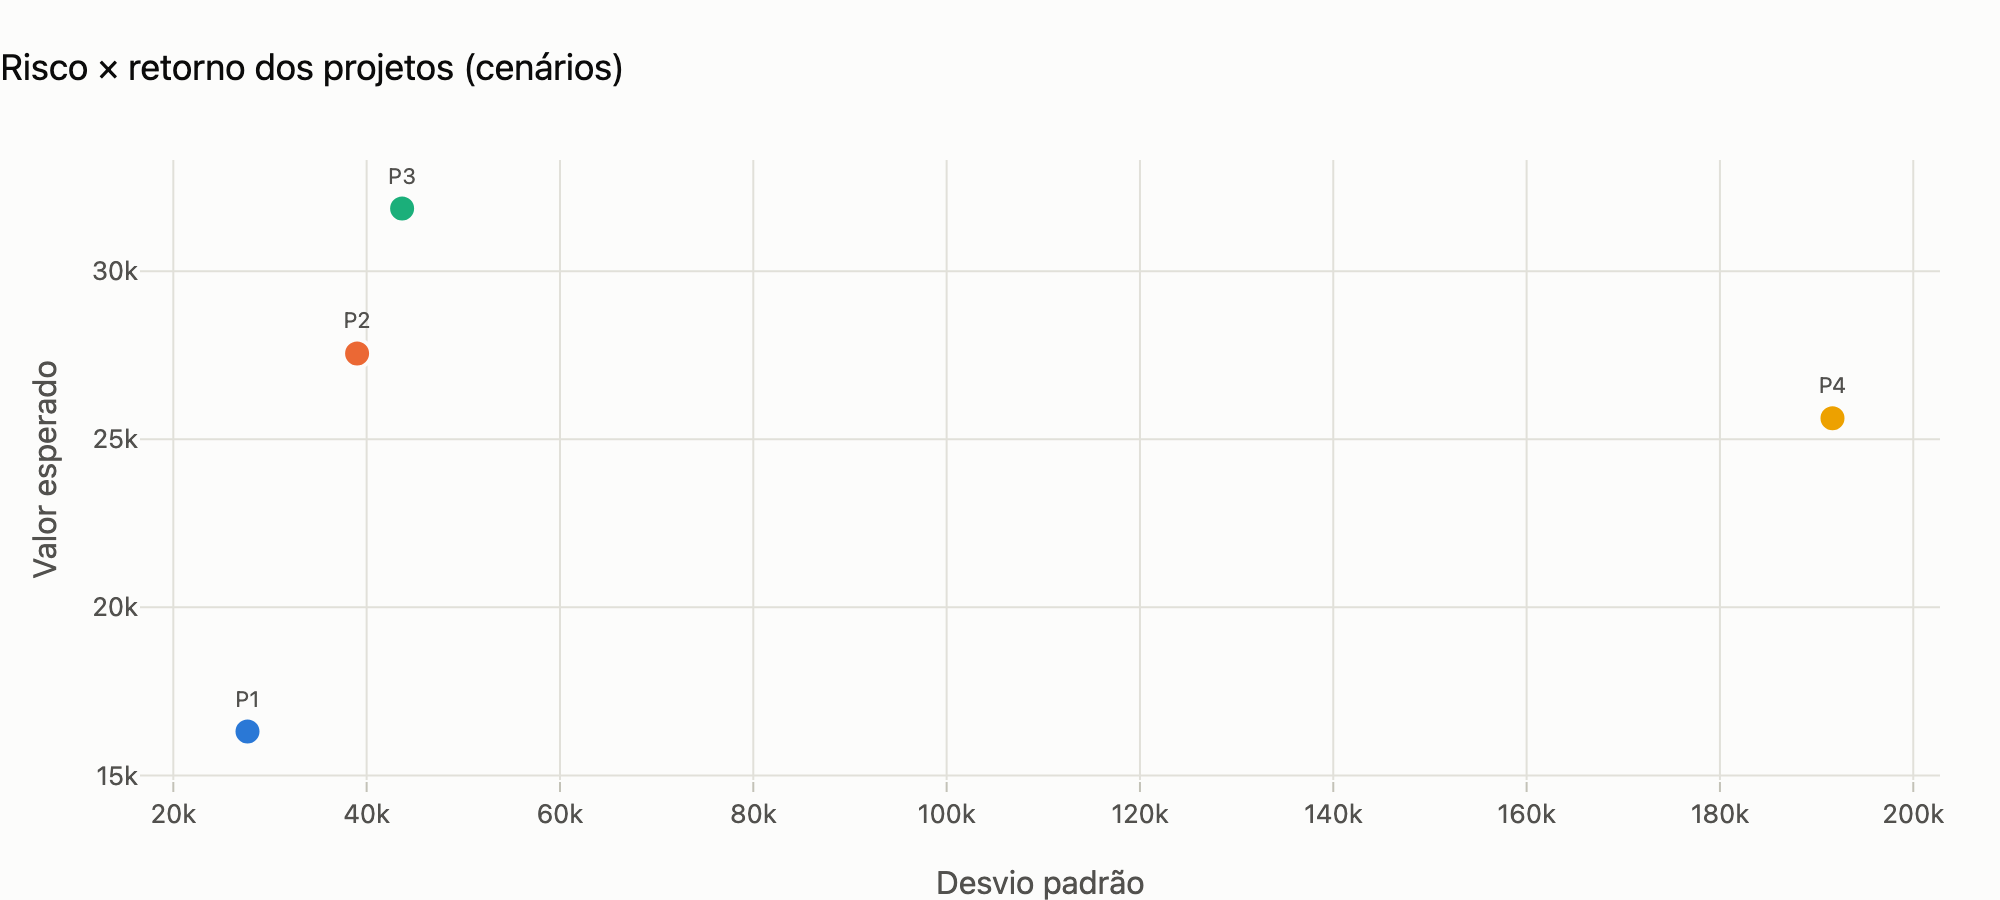

In [7]:
fig = viz.grafico_risco_retorno(resumo, x="Desvio padrão", y="Valor esperado", titulo="Risco × retorno dos projetos (cenários)")
viz.exportar(fig, f"{SAIDA}/risco_retorno")
fig

## 3. Taxa de desconto ajustada ao risco

As notas sugerem uma curva **CV → taxa de desconto**: projetos mais voláteis são descontados a taxas maiores.
A curva abaixo parte de 18% para CV = 0 e sobe até 30% para CV ≥ 2 (os valores são uma escolha de política
da empresa; a função só interpola).

In [8]:
curva = [(0.0, 0.18), (0.5, 0.20), (1.0, 0.22), (1.5, 0.25), (2.0, 0.30)]
taxas_ajustadas = ac.taxas_ajustadas(curva)
reaval = ac.reavaliar(taxas_ajustadas, cenario="Mais provável")
reaval.insert(0, "CV", resumo["CV"])
estilizar(reaval, tipos={"CV": "num", "Taxa": "pct"}, titulo="Caso-base reavaliado à taxa ajustada ao risco")

,CV,Taxa,VPL,RAU,IBC,TIR
Projeto,,,,,,
P1,"1,70","26,97%",($ 19.109),($ 7.395),"0,90","22,11%"
P2,"1,42","24,50%",$ 3.535,$ 1.301,"1,02","25,46%"
P3,"1,37","24,22%",($ 15.096),($ 4.682),"0,93","22,19%"
P4,"7,48","30,00%",($ 35.958),($ 13.606),"0,88","23,82%"


Descontados ao risco, **só P2 continua a criar valor** (por pouco); P4 é o mais penalizado, com VPL de
−$36.000. A curva escolhida é severa — o ponto é que o ranking muda completamente quando o risco entra na taxa.

## 4. Sensibilidade (tornado) e ponto de equilíbrio

Qual premissa mais move o VPL de cada projeto? Variamos cada parâmetro ±10% (ou entre limites dados),
mantendo os demais no caso-base.

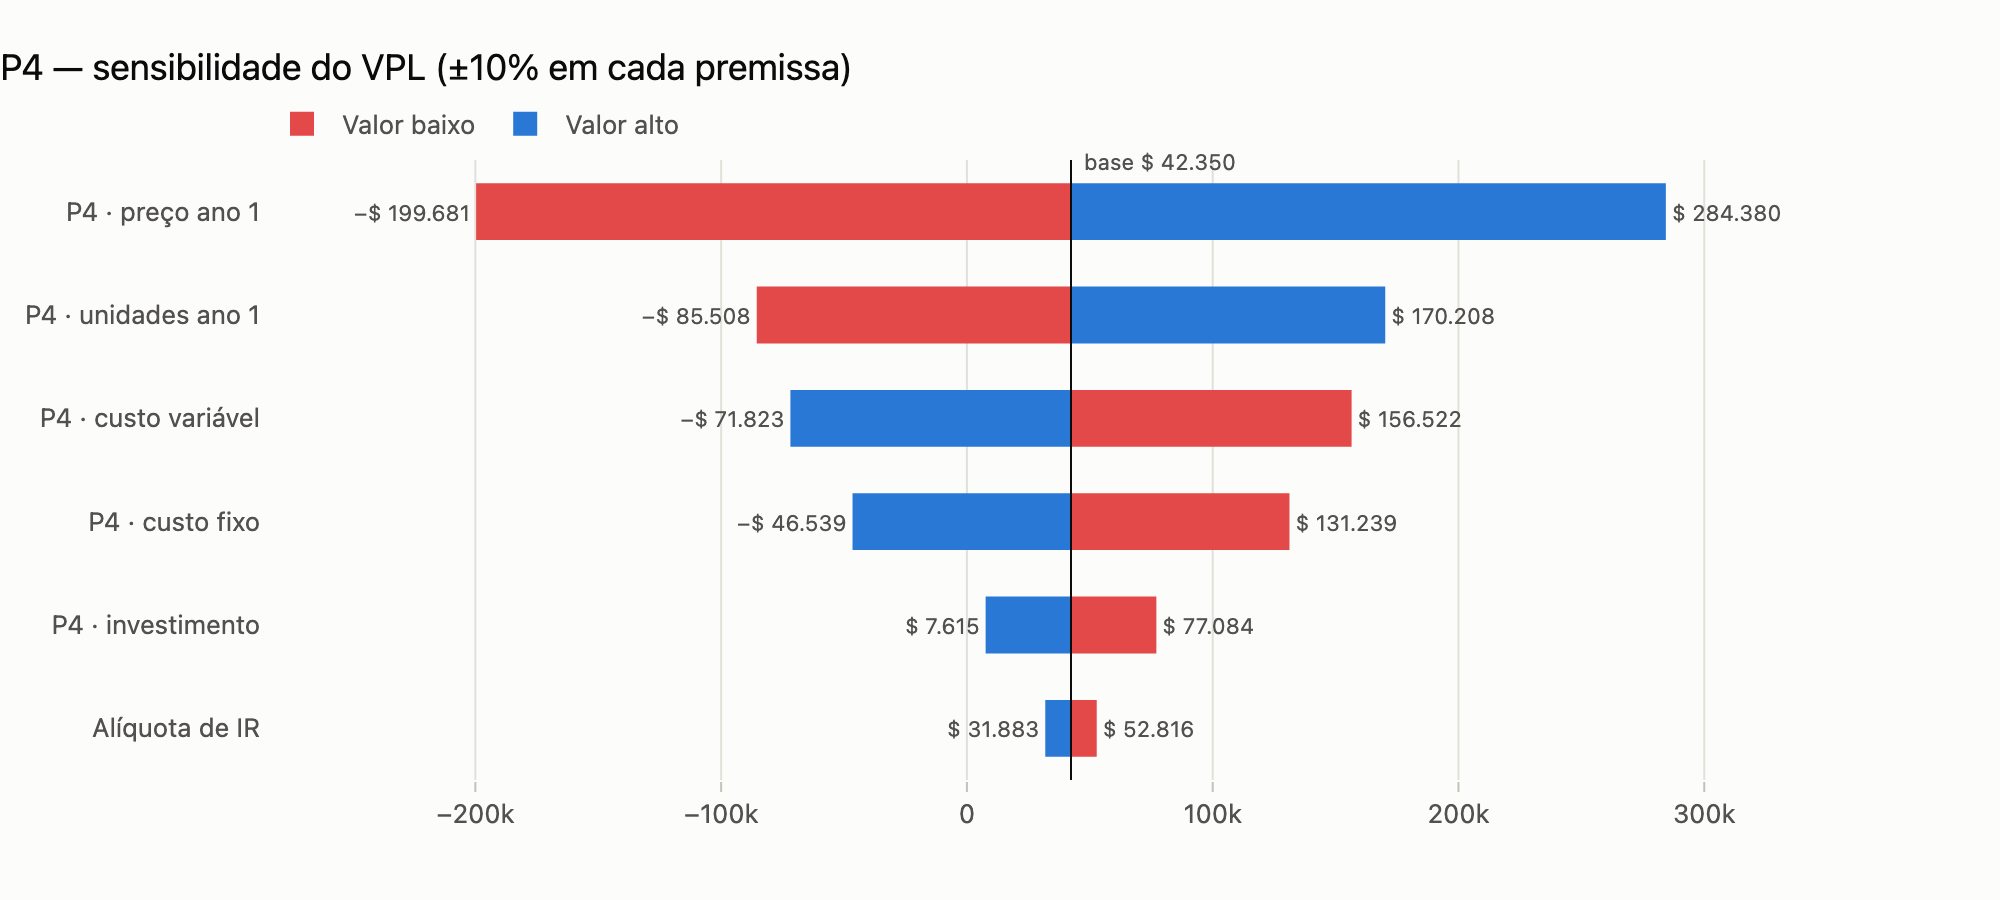

In [9]:
var_p4 = {"p4_preco": 0.10, "p4_unidades": 0.10, "p4_custo_var": 0.10, "p4_custo_fixo": 0.10, "p4_investimento": 0.10, "ir": (0.15, 0.25)}
sens_p4 = sensibilidade(modelo_p4, base, var_p4, taxa=K, rotulos=rotulos)
fig = viz.grafico_tornado(sens_p4, titulo="P4 — sensibilidade do VPL (±10% em cada premissa)")
viz.exportar(fig, f"{SAIDA}/tornado_p4")
fig

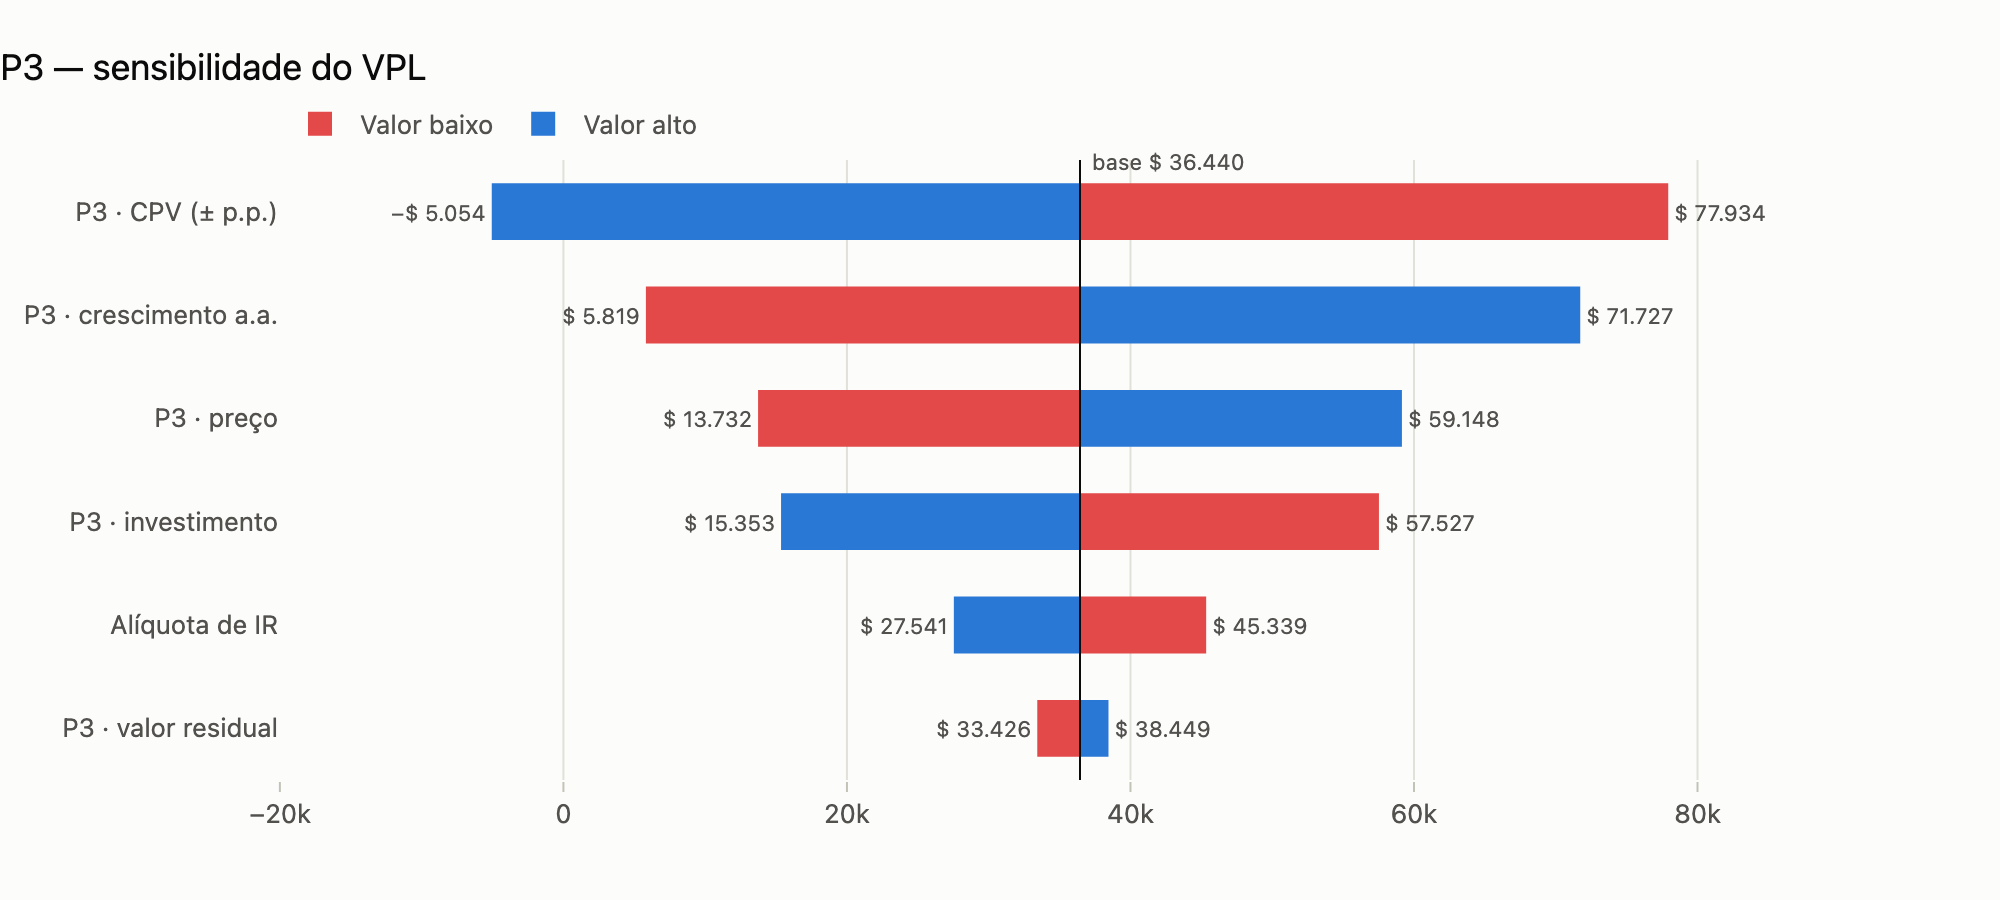

In [10]:
var_p3 = {"p3_preco": 0.10, "p3_crescimento": (0.05, 0.15), "p3_cpv_delta": (-0.03, 0.03), "p3_valor_residual": (30_000, 50_000), "p3_investimento": 0.10, "ir": (0.15, 0.25)}
sens_p3 = sensibilidade(modelo_p3, base, var_p3, taxa=K, rotulos=rotulos)
fig = viz.grafico_tornado(sens_p3, titulo="P3 — sensibilidade do VPL")
viz.exportar(fig, f"{SAIDA}/tornado_p3")
fig

In [11]:
eq = {
    "P4 · preço do ano 1 que zera o VPL": ponto_de_equilibrio(modelo_p4, base, "p4_preco", K),
    "P4 · unidades do ano 1 que zeram o VPL": ponto_de_equilibrio(modelo_p4, base, "p4_unidades", K),
    "P4 · custo fixo que zera o VPL": ponto_de_equilibrio(modelo_p4, base, "p4_custo_fixo", K),
    "P3 · crescimento a.a. que zera o VPL": ponto_de_equilibrio(modelo_p3, base, "p3_crescimento", K, intervalo=(-0.2, 0.3)),
    "P3 · preço que zera o VPL": ponto_de_equilibrio(modelo_p3, base, "p3_preco", K),
    "P2 · fator de receita que zera o VPL": ponto_de_equilibrio(modelo_p2, base, "p2_fator_receita", K),
    "P1 · unidades que zeram o VPL": ponto_de_equilibrio(modelo_p1, base, "p1_unidades", K),
}
pd.Series(eq, name="Ponto de equilíbrio").to_frame().style.format("{:,.3f}").set_caption("Quanto cada premissa pode piorar antes de o VPL ficar negativo")

,Ponto de equilíbrio
P4 · preço do ano 1 que zera o VPL,19.650
P4 · unidades do ano 1 que zeram o VPL,"29,006.329"
P4 · custo fixo que zera o VPL,"209,528.667"
P3 · crescimento a.a. que zera o VPL,0.040
P3 · preço que zera o VPL,5.037
P2 · fator de receita que zera o VPL,0.886
P1 · unidades que zeram o VPL,"11,281.365"


P4 vira negativo com uma queda de apenas **1,8% no preço** (de $20 para $19,65), de 3,3% no volume ou com
custo fixo 4,8% maior; P3 só fica negativo se o crescimento cair de 10% para 4% a.a. ou o preço de $6 para
$5,04 — margens de segurança muito diferentes.

## 5. Carteiras de dois projetos sob cenários

Como o VPL é aditivo, o VPL de cada carteira em cada cenário é a soma dos VPLs dos seus projetos.

In [12]:
import itertools

vpl_cen = ac.tabela("vpl")
probs = ac.probabilidades
linhas = {}
for a, b in itertools.combinations(vpl_cen.index, 2):
    v = vpl_cen.loc[a] + vpl_cen.loc[b]
    e = float((v * probs).sum())
    dp = float(np.sqrt((probs * (v - e) ** 2).sum()))
    linhas[f"{a} + {b}"] = {**v.to_dict(), "Valor esperado": e, "Desvio padrão": dp, "CV": dp / e if e else np.nan, "P(< 0)": float(probs[v.values < 0].sum())}
cart_cen = pd.DataFrame(linhas).T.sort_values("Valor esperado", ascending=False)
cart_cen.index.name = "Carteira"
estilizar(cart_cen, tipos={c.nome: "moeda" for c in cenarios}, titulo="Carteiras de dois projetos por cenário")

,Pessimista,Mais provável,Otimista,Valor esperado,Desvio padrão,CV,P(< 0)
Carteira,,,,,,,
P2 + P3,($ 64.631),$ 67.049,$ 168.214,$ 59.420,$ 82.676,"1,39","25,00%"
P3 + P4,($ 295.215),$ 78.790,$ 367.607,$ 57.493,$ 235.309,"4,09","25,00%"
P2 + P4,($ 291.595),$ 72.959,$ 358.394,$ 53.179,$ 230.655,"4,34","25,00%"
P1 + P3,($ 59.379),$ 55.342,$ 141.389,$ 48.173,$ 71.343,"1,48","25,00%"
P1 + P2,($ 55.759),$ 49.511,$ 132.176,$ 43.860,$ 66.685,"1,52","25,00%"
P1 + P4,($ 286.343),$ 61.252,$ 331.569,$ 41.932,$ 219.317,"5,23","25,00%"


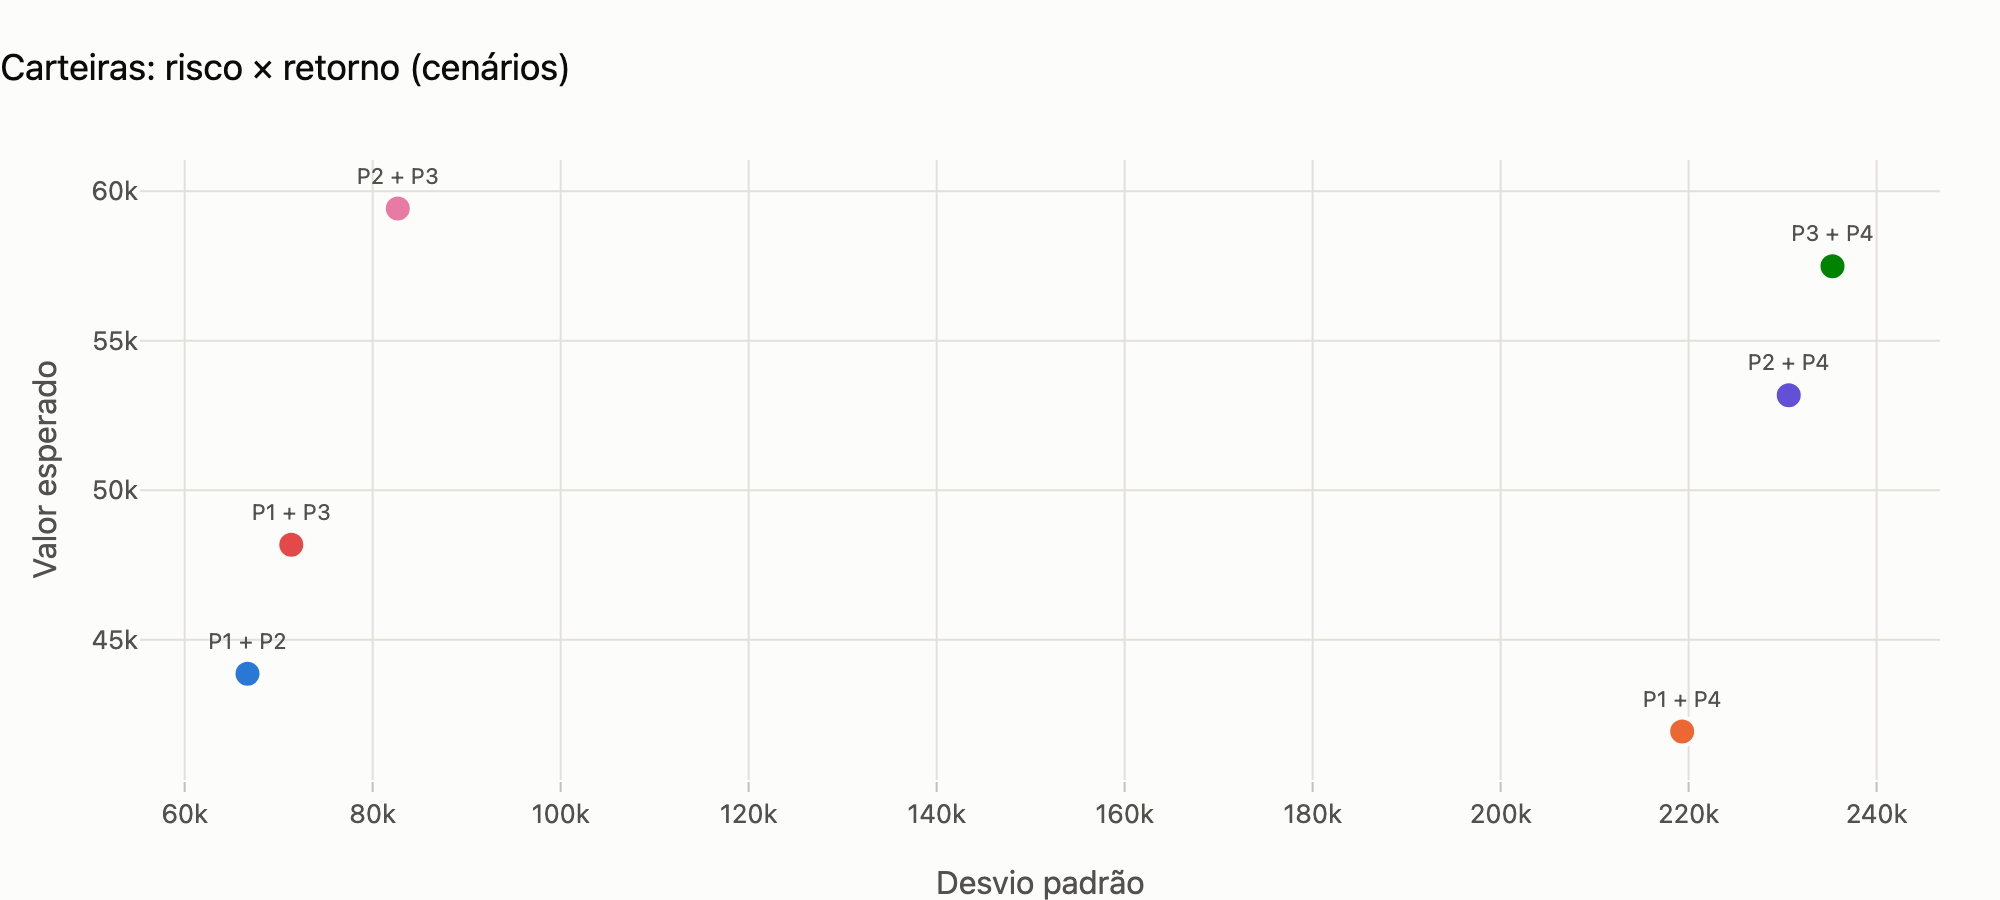

In [13]:
fig = viz.grafico_risco_retorno(cart_cen, x="Desvio padrão", y="Valor esperado", titulo="Carteiras: risco × retorno (cenários)")
viz.exportar(fig, f"{SAIDA}/carteiras_risco_retorno")
fig

## 6. Conclusões da análise de cenários

* **P4** é o melhor projeto no caso-base, mas é o mais arriscado por larga margem: CV de 7,5, VPL de
  −$261.000 no cenário pessimista e negativo quando descontado ao risco. Ele vive de preço e volume; o ponto
  de equilíbrio está a 1,8% de queda de preço.
* **P3** tem o maior VPL esperado e CV moderado; **P2** tem o melhor perfil quando o desconto é ajustado ao
  risco.
* A carteira **P2 + P3** tem o maior valor esperado e o menor risco entre as de maior retorno — a resposta
  "P4 + P3" do caso-base perde para ela assim que o risco entra na conta.

Cenários discretos, porém, só olham três estados do mundo. O notebook 4 faz a simulação de Monte Carlo para
obter a distribuição completa do VPL de cada projeto e de cada carteira.